# Taller 3 - EDA de FreeToGame
Lectura de datos crudos desde MongoDB, selección de variables y análisis exploratorio.

## 1. Conexión a MongoDB y lectura de la colección

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()
MONGO_URI = os.getenv("MONGODB_URI")
col = MongoClient(MONGO_URI)["taller3_db"]["raw_data"]
print("Documentos en taller3_db.raw_data:", col.count_documents({}))

Matplotlib is building the font cache; this may take a moment.


Documentos en taller3_db.raw_data: 416


## 2. Selección de variables
Se cargan los documentos y se conservan solo 7 columnas relevantes: id, título, género, plataforma, publisher, desarrollador y fecha de lanzamiento.

In [2]:
docs = list(col.find({}, {"title": 1, "genre": 1, "platform": 1,
                         "publisher": 1, "developer": 1, "release_date": 1}))
df = pd.DataFrame(docs).rename(columns={"_id": "id"})
df = df[["id", "title", "genre", "platform", "publisher", "developer", "release_date"]]
df.shape

(416, 7)

## 3. Limpieza
Se convierte `release_date` a fecha, se crea la columna `year` y se limpian espacios en texto.

In [3]:
for c in ["title", "genre", "platform", "publisher", "developer"]:
    df[c] = df[c].astype(str).str.strip()
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
df.head()

,id,title,genre,platform,publisher,developer,release_date,year
0,540,Overwatch,Shooter,PC (Windows),Activision Blizzard,Blizzard Entertainment,2022-10-04,2022
1,516,PUBG: BATTLEGROUNDS,Shooter,PC (Windows),"KRAFTON, Inc.","KRAFTON, Inc.",2022-01-12,2022
2,508,Enlisted,Shooter,PC (Windows),Gaijin Entertainment,Darkflow Software,2021-04-08,2021
3,642,Neverness to Everness,RPG,PC (Windows),Perfect World Entertainment,Hotta Studio,2026-04-29,2026
4,523,Fall Guys,Battle Royale,PC (Windows),Mediatonic,Mediatonic,2020-08-04,2020


## 4. Análisis exploratorio
### A. Inspección básica

In [4]:
df.head()

,id,title,genre,platform,publisher,developer,release_date,year
0,540,Overwatch,Shooter,PC (Windows),Activision Blizzard,Blizzard Entertainment,2022-10-04,2022
1,516,PUBG: BATTLEGROUNDS,Shooter,PC (Windows),"KRAFTON, Inc.","KRAFTON, Inc.",2022-01-12,2022
2,508,Enlisted,Shooter,PC (Windows),Gaijin Entertainment,Darkflow Software,2021-04-08,2021
3,642,Neverness to Everness,RPG,PC (Windows),Perfect World Entertainment,Hotta Studio,2026-04-29,2026
4,523,Fall Guys,Battle Royale,PC (Windows),Mediatonic,Mediatonic,2020-08-04,2020


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            416 non-null    int64         
 1   title         416 non-null    str           
 2   genre         416 non-null    str           
 3   platform      416 non-null    str           
 4   publisher     416 non-null    str           
 5   developer     416 non-null    str           
 6   release_date  416 non-null    datetime64[us]
 7   year          416 non-null    int32         
dtypes: datetime64[us](1), int32(1), int64(1), str(5)
memory usage: 24.5 KB


Conteo de valores nulos por columna:

In [6]:
df.isnull().sum()

id              0
title           0
genre           0
platform        0
publisher       0
developer       0
release_date    0
year            0
dtype: int64

### B. Cinco insights numéricos

In [7]:
# Insight 1: total de juegos y género más frecuente
print(f"1) Hay {len(df)} juegos; el género más común es '{df['genre'].value_counts().idxmax()}' "
      f"con {df['genre'].value_counts().max()} juegos.")

# Insight 2: publisher con más juegos
pub = df["publisher"].value_counts()
print(f"2) El publisher con más juegos es '{pub.idxmax()}' con {pub.max()} títulos.")

# Insight 3: distribución por plataforma
plat = df["platform"].value_counts(normalize=True) * 100
print("3) Distribución por plataforma (%):")
print(plat.round(1).to_string())

# Insight 4: año con más lanzamientos
yr = df["year"].value_counts()
print(f"4) El año con más lanzamientos es {int(yr.idxmax())} con {yr.max()} juegos.")

# Insight 5: año promedio y rango de lanzamiento
print(f"5) Año promedio de lanzamiento: {df['year'].mean():.1f} "
      f"(más antiguo: {int(df['year'].min())}, más reciente: {int(df['year'].max())}).")

1) Hay 416 juegos; el género más común es 'MMORPG' con 158 juegos.
2) El publisher con más juegos es 'R2 Games' con 6 títulos.
3) Distribución por plataforma (%):
platform
PC (Windows)                 82.7
Web Browser                  14.9
PC (Windows), Web Browser     2.4
4) El año con más lanzamientos es 2015 con 32 juegos.
5) Año promedio de lanzamiento: 2016.5 (más antiguo: 1997, más reciente: 2026).


### C. Visualizaciones
**Gráfico 1 (torta):** proporción de juegos por género (los 6 principales + 'Otros').

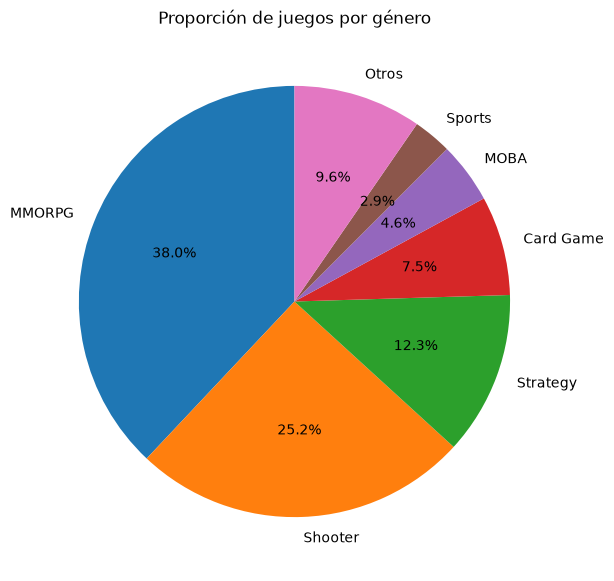

In [11]:
g = df["genre"].value_counts()
top = g.head(6)
if len(g) > 6:
    top["Otros"] = g.iloc[6:].sum()
plt.figure(figsize=(7, 7))
plt.pie(top, labels=top.index, autopct="%1.1f%%", startangle=90)
plt.title("Proporción de juegos por género")
plt.show()

**Gráfico 2 (barras):** los 10 publishers con más juegos.

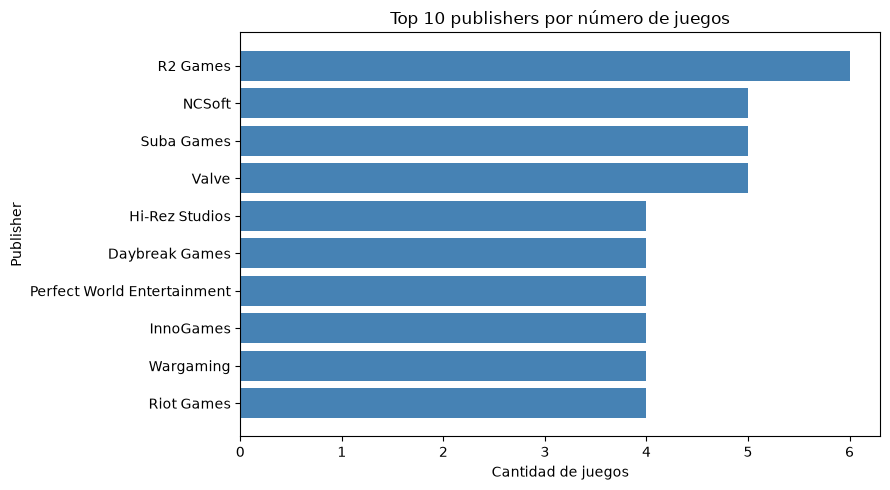

In [9]:
top_pub = df["publisher"].value_counts().head(10).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(top_pub.index, top_pub.values, color="steelblue")
plt.title("Top 10 publishers por número de juegos")
plt.xlabel("Cantidad de juegos")
plt.ylabel("Publisher")
plt.tight_layout()
plt.show()

**Gráfico 3 (histograma):** distribución de juegos por año de lanzamiento.

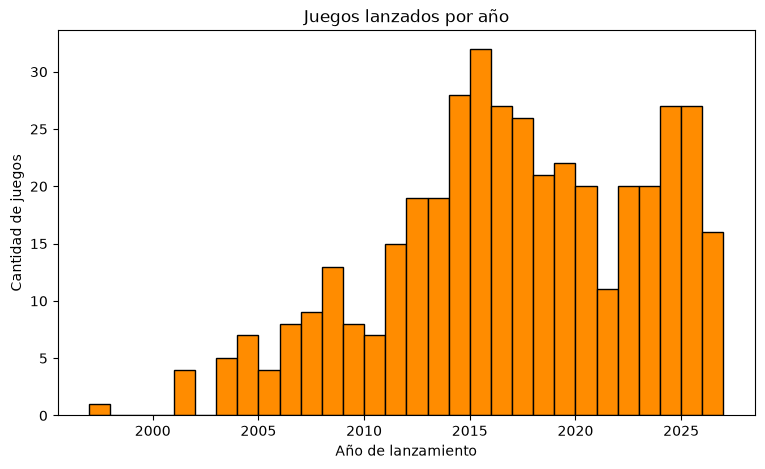

In [10]:
plt.figure(figsize=(9, 5))
plt.hist(df["year"].dropna(), bins=range(int(df["year"].min()), int(df["year"].max()) + 2),
         color="darkorange", edgecolor="black")
plt.title("Juegos lanzados por año")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Cantidad de juegos")
plt.show()

## 5. Conclusiones
Se trabajó con un total de 416 videojuegos gratuitos, obtenidos mediante la API de FreeToGame y almacenados en MongoDB. Al revisar los géneros, se encontró que el MMORPG es el más frecuente, con 158 juegos, que representan aproximadamente el 38 % del total. Esto muestra que hay una presencia importante de juegos de rol en línea dentro de este catálogo. Por otro lado, se observa que la oferta está bastante distribuida entre diferentes publishers, ya que R2 Games, que es el que más títulos tiene, cuenta solamente con 6 juegos. En cuanto a las plataformas, la mayoría de los videojuegos están disponibles para PC (Windows), con un 82,7 %, mientras que el 14,9 % funciona desde el navegador web y solo el 2,4 % está disponible en ambas opciones. Finalmente, al revisar los años de lanzamiento, se encontró que 2015 fue el año con mayor número de publicaciones, con 32 juegos. Además, el promedio de lanzamiento es 2016,5 y los años van desde 1997 hasta 2026. En general, estos resultados muestran que una buena parte de los videojuegos del catálogo se lanzó durante la década de 2010.